<a href="https://colab.research.google.com/github/anirudhanalwar/nlp_real_fake_news_detector/blob/main/fakeorrealnews.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

FAKE NEWS DETECTION PIPELINE


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

nltk.download('punkt')
nltk.download('punkt_tab')

nltk.download('stopwords')
nltk.download('wordnet')

RANDOM_STATE = 42


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


LOAD DATA

In [ ]:
true_df = pd.read_csv("True.csv")
fake_df = pd.read_csv("Fake.csv")

print("True shape:", true_df.shape)
print("Fake shape:", fake_df.shape)


True shape: (21417, 4)
Fake shape: (23481, 4)


REMOVE REUTERS PATTERN (BIAS CLEANING)

In [ ]:
def remove_reuters(text):
    text = re.sub(r'\(Reuters\).*?-', '', text)
    text = re.sub(r'Reuters', '', text)
    return text

true_df['text'] = true_df['text'].apply(remove_reuters)


ADD LABELS

In [ ]:
true_df['label'] = 1
fake_df['label'] = 0
print(true_df)

                                                   title  \
0      As U.S. budget fight looms, Republicans flip t...   
1      U.S. military to accept transgender recruits o...   
2      Senior U.S. Republican senator: 'Let Mr. Muell...   
3      FBI Russia probe helped by Australian diplomat...   
4      Trump wants Postal Service to charge 'much mor...   
...                                                  ...   
21412  'Fully committed' NATO backs new U.S. approach...   
21413  LexisNexis withdrew two products from Chinese ...   
21414  Minsk cultural hub becomes haven from authorities   
21415  Vatican upbeat on possibility of Pope Francis ...   
21416  Indonesia to buy $1.14 billion worth of Russia...   

                                                    text       subject  \
0      WASHINGTON  The head of a conservative Republi...  politicsNews   
1      WASHINGTON  Transgender people will be allowed...  politicsNews   
2      WASHINGTON  The special counsel investigation ... 

5. MERGE & SHUFFLE

In [ ]:
df = pd.concat([true_df, fake_df], axis=0)
df = df.sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(df['label'].value_counts())


label
0    23481
1    21417
Name: count, dtype: int64


COMBINE TITLE + TEXT

In [ ]:
df['content'] = df['title'] + " " + df['text']


TEXT PREPROCESSING

In [ ]:
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess(text):
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))

    tokens = word_tokenize(text)
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    return " ".join(tokens)

df['clean_text'] = df['content'].apply(preprocess)


TRAIN TEST SPLIT (80-20)


In [ ]:
X = df['clean_text']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)


TF-IDF FEATURE ENGINEERING

In [ ]:
vectorizer = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1,2)
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)


MODEL TRAINING

In [ ]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_tfidf, y_train)

# Naive Bayes
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)


MultinomialNB()

EVALUATION FUNCTION

In [ ]:
def evaluate(model, X_test, y_test):
    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("\nClassification Report:\n")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()


EVALUATE MODELS

Logistic Regression Performance
Accuracy: 0.9829621380846325

Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.98      0.98      4696
           1       0.98      0.99      0.98      4284

    accuracy                           0.98      8980
   macro avg       0.98      0.98      0.98      8980
weighted avg       0.98      0.98      0.98      8980



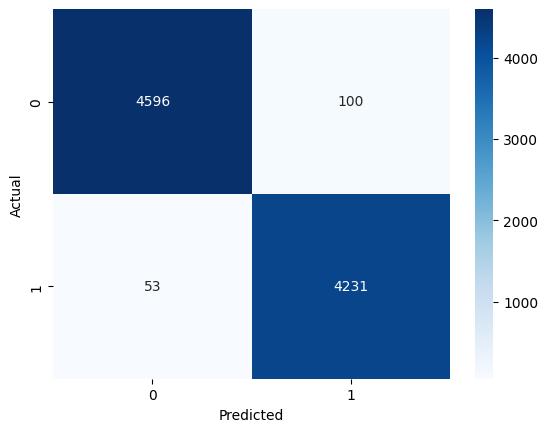

Naive Bayes Performance
Accuracy: 0.9389755011135857

Classification Report:

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      4696
           1       0.94      0.93      0.94      4284

    accuracy                           0.94      8980
   macro avg       0.94      0.94      0.94      8980
weighted avg       0.94      0.94      0.94      8980



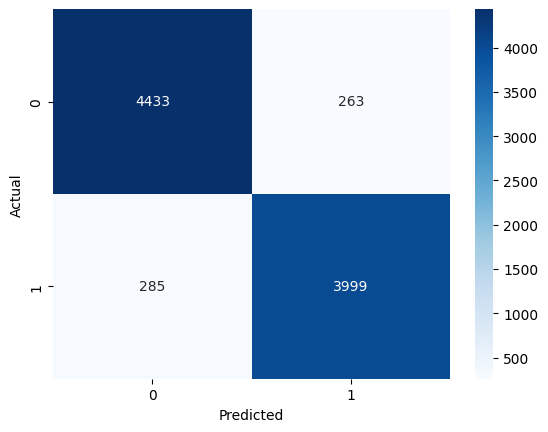

In [ ]:
print("Logistic Regression Performance")
evaluate(lr_model, X_test_tfidf, y_test)

print("Naive Bayes Performance")
evaluate(nb_model, X_test_tfidf, y_test)


FEATURE IMPORTANCE (LOGISTIC REGRESSION)

In [ ]:
feature_names = vectorizer.get_feature_names_out()
coefficients = lr_model.coef_[0]

top_fake = np.argsort(coefficients)[:20]
top_real = np.argsort(coefficients)[-20:]

print("Top 20 Words Indicating Fake News:")
for i in top_fake:
    print(feature_names[i])

print("\nTop 20 Words Indicating Real News:")
for i in top_real:
    print(feature_names[i])


Top 20 Words Indicating Fake News:
video
via
image
president trump
gop
hillary
mr
obama
even
image via
breaking
like
american
america
wire
rep
isi
sen
watch
know

Top 20 Words Indicating Real News:
comment
told reporter
est
presidential
minister
edt
said statement
london
washington president
president barack
representative
monday
nov
friday
thursday
tuesday
wednesday
president donald
washington
said


14. ERROR ANALYSIS (5 MISCLASSIFIED EXAMPLES)

In [ ]:
y_pred = lr_model.predict(X_test_tfidf)

misclassified_indices = np.where(y_pred != y_test)[0]

print("Showing 5 misclassified examples:\n")

for idx in misclassified_indices[:5]:
    print("Actual:", y_test.iloc[idx])
    print("Predicted:", y_pred[idx])
    print(X_test.iloc[idx][:500])
    print("="*80)


Showing 5 misclassified examples:

Actual: 1
Predicted: 0
whats dotard anyway kims insult trump north korean leader kim jong un confused lot englishspeakers though time intends nuclear program responding u president donald trump ’ bellicose warning pyongyang first speech united nation tuesday kim friday called trump “ dotard ” least translation state news agency kcna obscure word old late middle english around th century mean senile old person someone dotage although shakespeare tolkien used word barely heard day kim ’ statement caused twitter storm qu
Actual: 0
Predicted: 1
watch ny firefighter hold touching flag removal ceremony commissioner order u flag removed fire truck insane reason video progressivism get stronghold america patriotism strangled antiamerican left fire commissioner upstate new york ordered fire department remove u flag mounted firetrucks said display liability firefighter motoristsfire chief tory gallante arlington fire district poughkeepsie said board fire commis

# PREDICT NEW ARTICLE

In [ ]:
def predict_news(text, model, vectorizer):

    # Step 1 — Combine into same format
    text = text.lower()
    text = re.sub(r'\d+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))

    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [lemmatizer.lemmatize(word) for word in tokens]

    cleaned_text = " ".join(tokens)

    # Step 2 — Vectorize (ONLY transform, no fit)
    vectorized_text = vectorizer.transform([cleaned_text])

    # Step 3 — Predict
    prediction = model.predict(vectorized_text)[0]
    probability = model.predict_proba(vectorized_text)[0]

    if prediction == 1:
        label = "REAL"
    else:
        label = "FAKE"

    print("Prediction:", label)
    print("Confidence:", round(max(probability) * 100, 2), "%")

In [ ]:
sample_text = """
WASHINGTON - The U.S. Senate passed a new budget bill today after weeks of debate.
Officials stated the bill aims to reduce federal spending.
"""

predict_news(sample_text, lr_model, vectorizer)


Prediction: REAL
Confidence: 80.66 %


In [ ]:
sample_text = """
Shocking! Government secretly controlling citizens through hidden microchips!
This disturbing truth will blow your mind!
"""

predict_news(sample_text, lr_model, vectorizer)


Prediction: FAKE
Confidence: 94.26 %


In [ ]:
sample_text = """
sree anirudhan becomes president of india
"""

predict_news(sample_text, lr_model, vectorizer)

Prediction: FAKE
Confidence: 63.52 %


In [ ]:
sample_text = """
worlds best ai company is owned by thanos
"""

predict_news(sample_text, lr_model, vectorizer)

Prediction: FAKE
Confidence: 73.95 %


In [ ]:
sample_text = """
LONDON - The Bank of England announced it will keep interest rates unchanged
following its latest monetary policy meeting. Officials cited stable inflation
data and moderate economic growth as reasons for maintaining current rates.
"""


predict_news(sample_text, lr_model, vectorizer)

Prediction: REAL
Confidence: 71.52 %


In [ ]:
sample_text = """
ROME - Rail services between Rome and Naples were disrupted on Friday after authorities reported suspected sabotage to high-speed train infrastructure during the Winter Olympics period. Police said investigations are ongoing and security has been increased across major transit routes.
"""

predict_news(sample_text, lr_model, vectorizer)


Prediction: REAL
Confidence: 93.42 %


In [ ]:
sample_text = """
NEW YORK - U.S. stock markets closed slightly higher on Friday following the release of new economic data showing steady job growth. Analysts said investors responded positively to signs of stable inflation and continued corporate earnings strength.
"""
predict_news(sample_text, lr_model, vectorizer)

Prediction: REAL
Confidence: 94.24 %
